In [9]:
import os

project_folder = "/content/drive/MyDrive/ML-Project"
for root, dirs, files in os.walk(project_folder):
    print(root, "->", files)

/content/drive/MyDrive/ML-Project -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data/raw -> ['Banglore_traffic_Dataset.csv']
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data/processed -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/notebooks -> ['01_data_inspection.ipynb']
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/src -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/models -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/app -> []
/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/reports -> []


## Step 2: Load the dataset and take a first look

**What:** Read the CSV into a Pandas DataFrame, then check its size (rows, columns) and view the first few rows.

**Why:**
- A **DataFrame** is Pandas' table structure (rows = records, columns = features). Every later step (cleaning, plotting, model training) works on a DataFrame.
- We define `PROJECT_DIR` once and build all other paths from it. If the folder ever moves, we edit one line instead of hunting through the notebook.
- We check `.shape` first because the Kaggle page *claims* 8,936 rows and 16 columns. We verify instead of trusting.
- We use `.head()` to see real values. Column names alone don't tell us whether a column holds text, numbers, codes or dates.
- We set Pandas to show **all** columns, because by default it hides middle columns with "..." and we could miss one.

In [10]:
from google.colab import drive
import pandas as pd
import os
import glob

# 1. Mount Drive (safe to run again; does nothing if already mounted)
drive.mount('/content/drive')

# 2. Search the project folder (and all subfolders) for the CSV
search_pattern = "/content/drive/MyDrive/ML-Project/**/Banglore_traffic_Dataset.csv"
matches = glob.glob(search_pattern, recursive=True)
print("Files found:", matches)

# 3. Load it, or stop with a clear message
if len(matches) == 0:
    raise FileNotFoundError("CSV not found inside ML-Project. Check the filename and folder.")

file_path = matches[0]
df = pd.read_csv(file_path)

pd.set_option('display.max_columns', None)
print("Loaded from:", file_path)
print("Shape (rows, columns):", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files found: ['/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data/raw/Banglore_traffic_Dataset.csv']
Loaded from: /content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data/raw/Banglore_traffic_Dataset.csv
Shape (rows, columns): (8936, 16)


## Step 3: Data types, missing values and duplicates

**What:** Use `df.info()` to see each column's data type and non-null count, then count missing values and duplicate rows.

**Why:**
- **Data types**: a column that looks numeric might be stored as text (`object`), which models can't use directly. `Date` is likely stored as text and will need converting to a real date type later.
- **Missing values**: most ML algorithms cannot handle empty cells. We must know where they are and how many before deciding how to treat them.
- **Duplicates**: identical rows can inflate model scores. If a duplicate lands in both the training set and the test set, the model is "tested" on data it already saw.
- We do this **before** any plotting or modelling, because every later result depends on the data being sound.

In [11]:
# 1. Data types and non-null counts for every column
df.info()

# 2. Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Number of fully duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Date                                8936 non-null   object 
 1   Area Name                           8936 non-null   object 
 2   Road/Intersection Name              8936 non-null   object 
 3   Traffic Volume                      8936 non-null   int64  
 4   Average Speed                       8936 non-null   float64
 5   Travel Time Index                   8936 non-null   float64
 6   Congestion Level                    8936 non-null   float64
 7   Road Capacity Utilization           8936 non-null   float64
 8   Incident Reports                    8936 non-null   int64  
 9   Environmental Impact                8936 non-null   float64
 10  Public Transport Usage              8936 non-null   float64
 11  Traffic Signal Compliance           8936 no

## Step 4: Statistical summary of numeric columns

**What:** Use `df.describe()` to see count, mean, standard deviation, min, quartiles and max for every numeric column. Then count how many rows sit exactly at the suspected ceiling values.

**Why:**
- `describe()` shows the **range and shape** of each column in one table. Impossible values (negative speeds), suspicious maximums (many columns stopping at exactly 100) and wildly different scales all become visible.
- In the first rows, Congestion Level, Road Capacity Utilization and Travel Time Index repeatedly showed 100, 100 and 1.5. If a large share of rows have these exact values, the data is **capped (clipped)**. That matters because a model cannot learn differences between rows that all share the same value.
- Counting capped rows is a **measurement**, not a guess. We want a percentage to quote in the documentation.
- The mean is pulled by extreme values; the median (50%) is not. Comparing them tells us about skew.

In [12]:
# 1. Statistical summary of all numeric columns
print(df.describe().T.round(2).to_string())

# 2. How many rows sit exactly at the suspected ceiling values?
print("\nRows where Congestion Level == 100:",
      (df["Congestion Level"] == 100).sum())
print("Rows where Road Capacity Utilization == 100:",
      (df["Road Capacity Utilization"] == 100).sum())
print("Rows where Travel Time Index == 1.5:",
      (df["Travel Time Index"] == 1.5).sum())

# 3. Same counts as a percentage of all rows
print("\nPercent of rows with Congestion Level == 100:",
      round((df["Congestion Level"] == 100).mean() * 100, 2), "%")

                               count      mean       std      min       25%       50%       75%       max
Traffic Volume                8936.0  29236.05  13001.81  4233.00  19413.00  27600.00  38058.50  72039.00
Average Speed                 8936.0     39.45     10.71    20.00     31.78     39.20     46.64     89.79
Travel Time Index             8936.0      1.38      0.17     1.00      1.24      1.50      1.50      1.50
Congestion Level              8936.0     80.82     23.53     5.16     64.29     92.39    100.00    100.00
Road Capacity Utilization     8936.0     92.03     16.58    18.74     97.35    100.00    100.00    100.00
Incident Reports              8936.0      1.57      1.42     0.00      0.00      1.00      2.00     10.00
Environmental Impact          8936.0    108.47     26.00    58.47     88.83    105.20    126.12    194.08
Public Transport Usage        8936.0     45.09     20.21    10.01     27.34     45.17     62.43     79.98
Traffic Signal Compliance     8936.0     79.95

## Step 5: Check how the capped columns relate to each other (leakage test)

**What:** Compute the correlation between the numeric columns, focusing on Congestion Level, Road Capacity Utilization, Travel Time Index, Traffic Volume and Average Speed.

**Why:**
- Step 4 showed Congestion Level, Capacity Utilization and Travel Time Index are heavily capped and look related.
- **Correlation** measures how strongly two numeric columns move together, from -1 (perfect opposite) to +1 (perfect together), with 0 meaning no linear relationship.
- If a candidate target is almost perfectly correlated with a candidate input, a model will look excellent for a trivial reason. That is **data leakage**: the input effectively contains the answer, so the high score would not reflect real predictive ability.
- We check this **before** choosing a target, so we don't build and present a model that only looks good.
- We use Spearman correlation as well as Pearson. Pearson measures *straight-line* relationships; Spearman measures *ranking* relationships and copes better with capped, non-linear data like ours.

In [13]:
# Numeric columns only
num_cols = df.select_dtypes(include="number").columns

# Pearson correlation (straight-line relationship), all numeric columns
print("PEARSON correlation:")
print(df[num_cols].corr(method="pearson").round(2).to_string())

# Spearman correlation (rank-based), all numeric columns
print("\nSPEARMAN correlation:")
print(df[num_cols].corr(method="spearman").round(2).to_string())

PEARSON correlation:
                              Traffic Volume  Average Speed  Travel Time Index  Congestion Level  Road Capacity Utilization  Incident Reports  Environmental Impact  Public Transport Usage  Traffic Signal Compliance  Parking Usage  Pedestrian and Cyclist Count
Traffic Volume                          1.00          -0.34               0.70              0.84                       0.65              0.34                  1.00                   -0.00                       0.01          -0.03                         -0.55
Average Speed                          -0.34           1.00              -0.38             -0.36                      -0.25             -0.16                 -0.34                    0.02                       0.00           0.00                          0.21
Travel Time Index                       0.70          -0.38               1.00              0.75                       0.51              0.32                  0.70                   -0.00            

## Step 6: Test whether Environmental Impact is derived from Traffic Volume

**What:** Fit a straight line Environmental Impact = a x Traffic Volume + b and check how well it fits. Also look at the ratio between the two columns.

**Why:**
- The correlation of 1.00 suggests Environmental Impact adds no new information. A perfect fit by a straight line would prove it is a formula of Traffic Volume.
- If proven, we drop it: keeping a redundant column wastes model capacity and, if used to predict congestion, would be a leakage risk.
- This is a measurement, not an assumption, so we can state it in the viva with evidence.

In [14]:
import numpy as np

# Fit a straight line: Environmental Impact = slope * Traffic Volume + intercept
slope, intercept = np.polyfit(df["Traffic Volume"], df["Environmental Impact"], 1)
print("slope:", slope, " intercept:", intercept)

# How far is the straight-line prediction from the real value?
predicted = slope * df["Traffic Volume"] + intercept
max_error = (df["Environmental Impact"] - predicted).abs().max()
print("Largest difference between real and line-predicted value:", max_error)

# Exact correlation to more decimals
print("Exact correlation:",
      df["Traffic Volume"].corr(df["Environmental Impact"]))

slope: 0.001999999999999999  intercept: 50.000000000000014
Largest difference between real and line-predicted value: 5.684341886080802e-14
Exact correlation: 1.0


In [15]:
for col in ["Area Name", "Road/Intersection Name",
            "Weather Conditions", "Roadwork and Construction Activity"]:
    print(f"\n{col}  ({df[col].nunique()} unique values)")
    print(df[col].value_counts().to_string())

print("\nDate range:", df["Date"].min(), "to", df["Date"].max())
print("Unique dates:", df["Date"].nunique())


Area Name  (8 unique values)
Area Name
Indiranagar        1720
M.G. Road          1501
Koramangala        1364
Jayanagar          1173
Hebbal              950
Whitefield          942
Yeshwanthpur        734
Electronic City     552

Road/Intersection Name  (16 unique values)
Road/Intersection Name
100 Feet Road          860
CMH Road               860
Anil Kumble Circle     759
Trinity Circle         742
Sony World Junction    684
Sarjapur Road          680
South End Circle       593
Jayanagar 4th Block    580
Marathahalli Bridge    492
Ballari Road           476
Hebbal Flyover         474
ITPL Main Road         450
Yeshwanthpur Circle    373
Tumkur Road            361
Hosur Road             277
Silk Board Junction    275

Weather Conditions  (5 unique values)
Weather Conditions
Clear       5426
Overcast    1296
Fog          959
Rain         827
Windy        428

Roadwork and Construction Activity  (2 unique values)
Roadwork and Construction Activity
No     8054
Yes     882

Date range:

## Step 8: Check the Area-Road relationship and daily row counts

**What:** Cross-tabulate Area Name against Road/Intersection Name, and count how many rows exist per date.

**Why:**
- If each road belongs to exactly one area, then Road and Area carry overlapping information. Encoding both would add redundant columns, so we need to know before feature engineering.
- Rows per date shows whether the dataset is a complete grid (every road measured every day) or a sparse sample. That decides whether we can build "yesterday's traffic" style features and how a time-based split behaves.
- Both are quick, evidence-based checks that avoid assumptions about how the data was built.

In [16]:
# 1. Which areas does each road appear in?
road_area = df.groupby("Road/Intersection Name")["Area Name"].nunique()
print("Number of distinct areas per road:")
print(road_area.to_string())

# 2. Rows per date
rows_per_date = df.groupby("Date").size()
print("\nRows per date (summary):")
print(rows_per_date.describe().round(2).to_string())

# 3. Does each road appear at most once per date?
print("\nMax rows for the same road on the same date:",
      df.groupby(["Date", "Road/Intersection Name"]).size().max())

Number of distinct areas per road:
Road/Intersection Name
100 Feet Road          1
Anil Kumble Circle     1
Ballari Road           1
CMH Road               1
Hebbal Flyover         1
Hosur Road             1
ITPL Main Road         1
Jayanagar 4th Block    1
Marathahalli Bridge    1
Sarjapur Road          1
Silk Board Junction    1
Sony World Junction    1
South End Circle       1
Trinity Circle         1
Tumkur Road            1
Yeshwanthpur Circle    1

Rows per date (summary):
count    952.00
mean       9.39
std        1.73
min        4.00
25%        8.00
50%        9.00
75%       11.00
max       15.00

Max rows for the same road on the same date: 1


## Phase 2, Step 1: Convert Date to a real date type and view key distributions

**What:** Convert the `Date` column from text to a Pandas datetime type, confirm it worked, then plot histograms of Congestion Level and Traffic Volume.

**Why:**
- `Date` is stored as text (`object`). Pandas can only extract year, month or weekday from a true datetime column, and time-based analysis and splitting depend on this.
- A **histogram** shows how often values fall in each range (the distribution). Before modelling, we must see the shape of the target. We expect Congestion Level to show a large spike at 100 because of capping (43.46% of rows), and we want to see it with our own eyes.
- Traffic Volume is plotted next to it to see whether it is spread out or clustered, since it is our strongest candidate input.
- We create a new column `Date_dt`-style conversion in place (`df["Date"] = ...`) because the raw CSV file on disk stays untouched, so nothing is lost.

Date dtype: datetime64[ns]
Earliest: 2022-01-01 00:00:00 | Latest: 2024-08-09 00:00:00


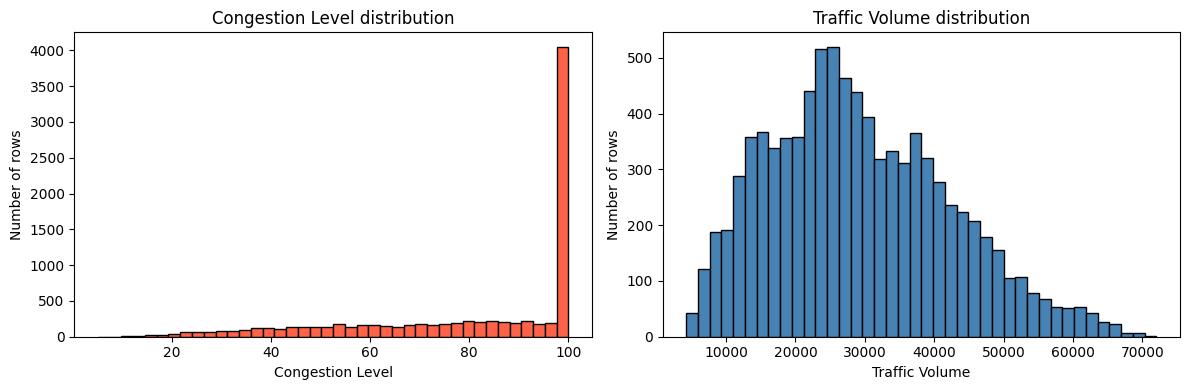

In [17]:
import matplotlib.pyplot as plt

# Convert text dates into real datetime values
df["Date"] = pd.to_datetime(df["Date"])

# Confirm the conversion
print("Date dtype:", df["Date"].dtype)
print("Earliest:", df["Date"].min(), "| Latest:", df["Date"].max())

# Histograms of target and a key input
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Congestion Level"], bins=40, color="tomato", edgecolor="black")
axes[0].set_title("Congestion Level distribution")
axes[0].set_xlabel("Congestion Level")
axes[0].set_ylabel("Number of rows")

axes[1].hist(df["Traffic Volume"], bins=40, color="steelblue", edgecolor="black")
axes[1].set_title("Traffic Volume distribution")
axes[1].set_xlabel("Traffic Volume")
axes[1].set_ylabel("Number of rows")

plt.tight_layout()
plt.show()

## Phase 2, Step 2: Traffic patterns by road, area, weather and roadwork

**What:** Compute the average Traffic Volume and Congestion Level for each Area, Road, Weather condition and Roadwork status. Also compute the share of rows at the 100 ceiling for each group.

**Why:**
- The Traffic Volume histogram had several bumps, which suggests different roads have different typical volumes. Grouping by road tests this directly.
- Averages alone are misleading for Congestion Level because 43% of values are capped at 100. So we also compute the **percentage of rows at 100**, which shows how often each group is fully congested.
- This answers project Objectives 3 and 4: which areas are congestion-prone, and whether weather and roadwork matter.
- We use `groupby`, which splits the table into groups, computes a statistic for each group, and combines the results. It is the core Pandas tool for EDA.

In [18]:
# Helper column: True if this row is at the congestion ceiling
df["At_Ceiling"] = (df["Congestion Level"] == 100)

def summarize(group_col):
    out = df.groupby(group_col).agg(
        rows=("Congestion Level", "size"),
        avg_volume=("Traffic Volume", "mean"),
        avg_congestion=("Congestion Level", "mean"),
        pct_at_100=("At_Ceiling", "mean"),
    )
    out["pct_at_100"] = (out["pct_at_100"] * 100).round(1)
    out[["avg_volume", "avg_congestion"]] = out[["avg_volume", "avg_congestion"]].round(1)
    return out.sort_values("avg_congestion", ascending=False)

for col in ["Area Name", "Road/Intersection Name",
            "Weather Conditions", "Roadwork and Construction Activity"]:
    print(f"\n=== By {col} ===")
    print(summarize(col).to_string())


=== By Area Name ===
                 rows  avg_volume  avg_congestion  pct_at_100
Area Name                                                    
Koramangala      1364     40832.3            94.0        75.5
M.G. Road        1501     35300.4            90.6        63.3
Indiranagar      1720     32284.4            87.6        58.3
Hebbal            950     26533.2            80.1        38.0
Jayanagar        1173     24601.3            77.0        27.6
Whitefield        942     21295.1            69.1        15.5
Yeshwanthpur      734     18931.5            62.4         7.2
Electronic City   552     16346.6            54.5         3.1

=== By Road/Intersection Name ===
                        rows  avg_volume  avg_congestion  pct_at_100
Road/Intersection Name                                              
Sony World Junction      684     41470.8            94.1        77.0
Sarjapur Road            680     40190.0            93.8        74.0
Anil Kumble Circle       759     35251.8       

## Phase 2, Step 3: Traffic patterns over time

**What:** Extract year, month, weekday and weekend flag from Date, then compute average volume and congestion for each, and the average per month across years.

**Why:**
- Objective 4 asks for peak periods. The data has no hour, so the finest time resolution we can analyze is the day: weekday, month and season.
- We extract the parts from the datetime column with `.dt`, which only works because we converted Date earlier.
- If congestion differs by weekday (e.g. weekends lower), weekday is a useful feature. If all weekdays look identical, it adds nothing, and we want to know before feature engineering.
- We also check the year trend, because a clear upward or downward drift matters for a **time-based train/test split**: test data from the latest period would differ from training data.

In [19]:
# Extract time parts from the datetime column
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.day_name()
df["Is_Weekend"] = df["Date"].dt.dayofweek >= 5

def time_summary(col, order=None):
    out = df.groupby(col).agg(
        rows=("Congestion Level", "size"),
        avg_volume=("Traffic Volume", "mean"),
        avg_congestion=("Congestion Level", "mean"),
        pct_at_100=("At_Ceiling", "mean"),
    )
    out["pct_at_100"] = (out["pct_at_100"] * 100).round(1)
    out[["avg_volume", "avg_congestion"]] = out[["avg_volume", "avg_congestion"]].round(1)
    if order is not None:
        out = out.reindex(order)
    return out

days = ["Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"]

print("=== By Weekday ===")
print(time_summary("Weekday", days).to_string())
print("\n=== Weekend vs weekday ===")
print(time_summary("Is_Weekend").to_string())
print("\n=== By Month (all years combined) ===")
print(time_summary("Month").to_string())
print("\n=== By Year ===")
print(time_summary("Year").to_string())

=== By Weekday ===
           rows  avg_volume  avg_congestion  pct_at_100
Weekday                                                
Monday     1296     29510.2            81.4        43.8
Tuesday    1309     28911.3            80.3        42.8
Wednesday  1266     29697.6            81.3        44.9
Thursday   1250     29530.4            81.2        43.4
Friday     1253     28842.8            80.3        43.0
Saturday   1290     29063.0            80.3        42.0
Sunday     1272     29105.3            81.0        44.4

=== Weekend vs weekday ===
            rows  avg_volume  avg_congestion  pct_at_100
Is_Weekend                                              
False       6374     29297.2            80.9        43.6
True        2562     29084.0            80.6        43.2

=== By Month (all years combined) ===
       rows  avg_volume  avg_congestion  pct_at_100
Month                                              
1       887     28830.1            79.5        43.0
2       793     29147.9   

## Phase 2, Step 4: Correlation heatmap and Phase 2 wrap-up

**What:** Draw a heatmap of Spearman correlations for the numeric columns, leaving out Environmental Impact (an exact copy of Traffic Volume).

**Why:**
- A heatmap shows the whole correlation table as colours, so patterns are visible at a glance. It is a standard EDA figure and examiners expect it.
- We use Spearman because capped data bends straight-line relationships (as seen in Phase 1).
- We drop Environmental Impact to avoid a duplicate row and column of identical values.
- `annot=True` prints the numbers inside the cells, and a fixed range of -1 to 1 keeps colours comparable.

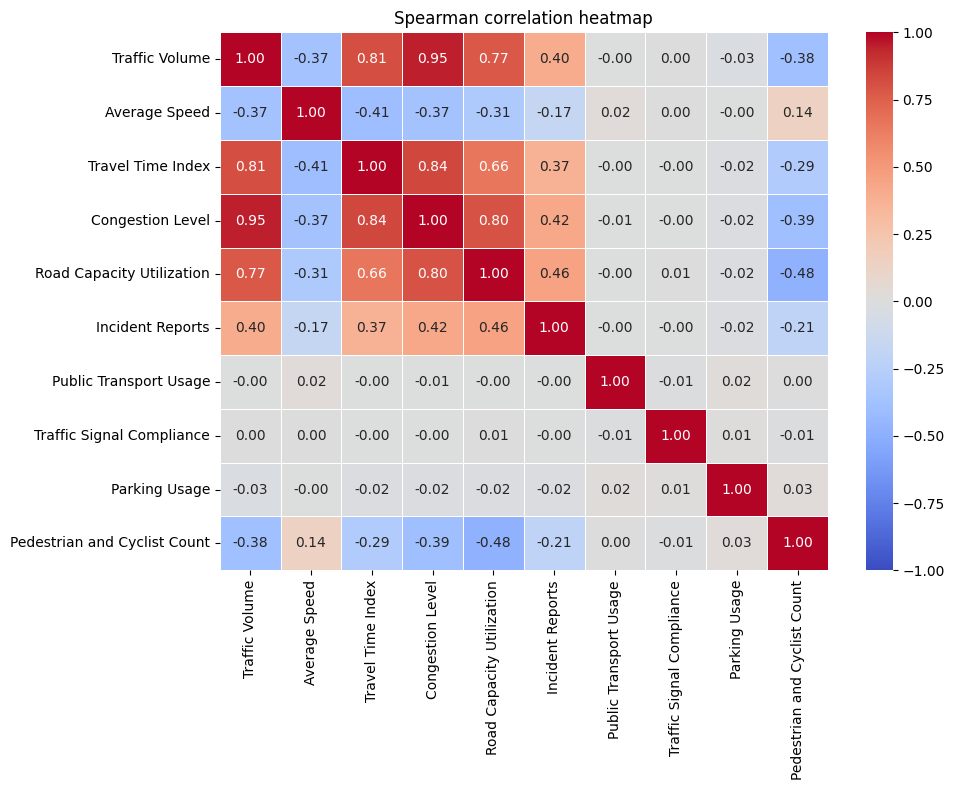

In [20]:
import seaborn as sns

cols = ["Traffic Volume", "Average Speed", "Travel Time Index",
        "Congestion Level", "Road Capacity Utilization", "Incident Reports",
        "Public Transport Usage", "Traffic Signal Compliance",
        "Parking Usage", "Pedestrian and Cyclist Count"]

corr = df[cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Spearman correlation heatmap")
plt.tight_layout()
plt.show()

## Phase 2 Summary

- Congestion Level is capped at 100 (43.46% of rows), so classification is the main task.
- Road/Area is the dominant signal; the ranking of areas by congestion matches the ranking by volume.
- Weather, roadwork, weekday, month and year show no meaningful effect on congestion or volume.
- Public Transport Usage, Signal Compliance and Parking Usage are uncorrelated with everything and will be excluded.
- Peak-hour analysis is not possible because the data has no time of day.
- Results do not match real-world Bangalore (e.g. Silk Board is among the least congested), so findings describe this dataset only.

## Phase 3, Step 1: Time-based train/test split

**What:** Sort the data by date, then use the earliest ~80% of days as the training set and the latest ~20% as the test set. Put the cut on a date boundary so no single day is split between the two sets.

**Why:**
- The test set must act like "future data the model has never seen." Training on earlier dates and testing on later ones imitates real use, where we predict tomorrow from the past. This avoids **temporal leakage**.
- A random split would mix days from all periods into both sets. Neighbouring days are often similar, so the model could be "tested" on days right next to ones it trained on, and the score would look better than it really is.
- Splitting on a **date boundary** matters because each date has several roads. A day cut in half would put some of its roads in training and some in test.
- We split **before** looking at class thresholds, scaling or encoding. Any statistic computed on the full data would let test information leak into training.
- Phase 2 showed no year-to-year trend, so train and test should be similar in distribution. We verify that below rather than assume it.

In [21]:
# Sort by date so "earlier" and "later" have a clear meaning
df = df.sort_values("Date").reset_index(drop=True)

# Find the date where 80% of the rows have been passed
cutoff_idx = int(len(df) * 0.8)
cutoff_date = df.loc[cutoff_idx, "Date"]

# Everything before the cutoff date -> train, from the cutoff date onward -> test
train = df[df["Date"] < cutoff_date].copy()
test = df[df["Date"] >= cutoff_date].copy()

print("Cutoff date:", cutoff_date.date())
print(f"Train: {len(train)} rows ({len(train)/len(df)*100:.1f}%)  "
      f"{train['Date'].min().date()} to {train['Date'].max().date()}")
print(f"Test : {len(test)} rows ({len(test)/len(df)*100:.1f}%)  "
      f"{test['Date'].min().date()} to {test['Date'].max().date()}")

# Safety check: no overlap in time
print("Train ends before test starts:", train["Date"].max() < test["Date"].min())

# Do train and test look similar?
for name, part in [("Train", train), ("Test", test)]:
    print(f"{name}: avg congestion = {part['Congestion Level'].mean():.1f}, "
          f"% at 100 = {(part['Congestion Level'] == 100).mean()*100:.1f}%, "
          f"avg volume = {part['Traffic Volume'].mean():.0f}")

Cutoff date: 2024-02-01
Train: 7145 rows (80.0%)  2022-01-01 to 2024-01-31
Test : 1791 rows (20.0%)  2024-02-01 to 2024-08-09
Train ends before test starts: True
Train: avg congestion = 80.7, % at 100 = 43.2%, avg volume = 29220
Test: avg congestion = 81.2, % at 100 = 44.6%, avg volume = 29298


## Phase 3, Step 2: Choose Low / Medium / High thresholds (training data only)

**What:** Look at the distribution of Congestion Level in the training set only, and compare how many rows would fall into each class under a few candidate cut-off pairs.

**Why:**
- A model needs discrete classes. We convert the numeric Congestion Level into Low / Medium / High.
- Thresholds are a decision made from data, so they must come from the **training set only**. If we used the full dataset, test information would influence how classes are defined, a subtle form of data leakage.
- Fixed numeric thresholds are easy to explain in a viva ("High means 90 or above") and stay the same for new user inputs in the dashboard.
- 43% of rows sit at exactly 100, so the High class will be large. We look at class sizes before committing, to make sure no class is so small that the model cannot learn it.

In [22]:
import numpy as np

y_train = train["Congestion Level"]

# 1. Quantiles of the training target
print("Training quantiles of Congestion Level:")
print(y_train.quantile([0.05, 0.10, 0.25, 0.33, 0.50, 0.67, 0.75, 0.90]).round(1).to_string())

# 2. Class sizes under candidate (low_cut, high_cut) pairs
candidates = [(50, 80), (50, 90), (60, 90), (60, 99.99), (70, 99.99)]

print("\nClass shares (%) in TRAIN for each candidate:")
for low_cut, high_cut in candidates:
    low = (y_train < low_cut).mean() * 100
    high = (y_train >= high_cut).mean() * 100
    mid = 100 - low - high
    print(f"Low < {low_cut}, High >= {high_cut}:  "
          f"Low {low:.1f}% | Medium {mid:.1f}% | High {high:.1f}%")

Training quantiles of Congestion Level:
0.05     33.1
0.10     42.9
0.25     64.2
0.33     74.5
0.50     92.2
0.67    100.0
0.75    100.0
0.90    100.0

Class shares (%) in TRAIN for each candidate:
Low < 50, High >= 80:  Low 14.6% | Medium 23.4% | High 62.0%
Low < 50, High >= 90:  Low 14.6% | Medium 33.2% | High 52.2%
Low < 60, High >= 90:  Low 21.8% | Medium 26.0% | High 52.2%
Low < 60, High >= 99.99:  Low 21.8% | Medium 35.0% | High 43.2%
Low < 70, High >= 99.99:  Low 29.3% | Medium 27.5% | High 43.2%


## Phase 3, Step 3: Create the Low / Medium / High target

**What:** Convert Congestion Level into three classes using fixed thresholds chosen from the training data: Low (< 60), Medium (60 to < 100), High (= 100). Apply the same thresholds to train and test, then check class balance in both.

**Why:**
- Classification metrics (accuracy, precision, recall, F1) need discrete classes.
- High = 100 because 43% of training rows sit exactly at the ceiling; this keeps the capped block together as one meaningful class ("fully saturated").
- Thresholds are fixed numbers learned from the training set only, so test rows are labelled with the same rules without influencing them.
- We check the test class shares to confirm the classes exist in both sets in similar proportions.

In [23]:
LOW_CUT = 60      # below this -> Low
HIGH_CUT = 100    # at or above this -> High (the capped value)

def to_class(value):
    if value < LOW_CUT:
        return "Low"
    elif value >= HIGH_CUT:
        return "High"
    else:
        return "Medium"

# Apply the SAME rule to both sets
train["Congestion_Class"] = train["Congestion Level"].apply(to_class)
test["Congestion_Class"] = test["Congestion Level"].apply(to_class)

# Check class balance in both
for name, part in [("Train", train), ("Test", test)]:
    print(f"\n{name} class counts:")
    counts = part["Congestion_Class"].value_counts()
    shares = (part["Congestion_Class"].value_counts(normalize=True) * 100).round(1)
    print(pd.DataFrame({"rows": counts, "percent": shares}).to_string())


Train class counts:
                  rows  percent
Congestion_Class               
High              3085     43.2
Medium            2503     35.0
Low               1557     21.8

Test class counts:
                  rows  percent
Congestion_Class               
High               799     44.6
Medium             602     33.6
Low                390     21.8


## Phase 3, Step 4: Select features and one-hot encode (fit on train only)

**What:** Define two feature lists (Scenario 1 without Traffic Volume/Average Speed, Scenario 2 with them), build the final X (inputs) and y (target) for train and test, and one-hot encode the categorical columns using an encoder fitted on the training set only.

**Why:**
- Leakage-prone and noise columns are excluded, based on the evidence from Phases 1 and 2.
- Machine-learning models need numbers. One-hot encoding turns each category into a 0/1 column without implying a false order.
- The encoder learns the category list from `train` only, then transforms both sets. This mimics real use: the model only knows what it learned in training.
- `handle_unknown="ignore"` means an unseen category in new data becomes all zeros instead of crashing the app later.
- Two scenarios let us report honestly how much the near-leaky columns inflate performance.

In [24]:
from sklearn.preprocessing import OneHotEncoder

# Prepare simple 0/1 columns
for part in (train, test):
    part["Roadwork_Flag"] = (part["Roadwork and Construction Activity"] == "Yes").astype(int)
    part["Is_Weekend"] = part["Is_Weekend"].astype(int)

# Feature lists
cat_cols = ["Road/Intersection Name", "Weather Conditions", "Weekday"]
num_base = ["Incident Reports", "Roadwork_Flag", "Is_Weekend", "Month"]
num_extra = ["Traffic Volume", "Average Speed"]   # Scenario 2 only

# Fit encoder on TRAIN only
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[cat_cols])

def build_X(part, include_extra):
    cat_array = encoder.transform(part[cat_cols])
    cat_df = pd.DataFrame(cat_array,
                          columns=encoder.get_feature_names_out(cat_cols),
                          index=part.index)
    num_list = num_base + (num_extra if include_extra else [])
    return pd.concat([part[num_list], cat_df], axis=1)

X_train_s1, X_test_s1 = build_X(train, False), build_X(test, False)
X_train_s2, X_test_s2 = build_X(train, True),  build_X(test, True)
y_train_cls = train["Congestion_Class"]
y_test_cls = test["Congestion_Class"]

print("Scenario 1 shapes:", X_train_s1.shape, X_test_s1.shape)
print("Scenario 2 shapes:", X_train_s2.shape, X_test_s2.shape)
print("\nScenario 1 columns:")
print(list(X_train_s1.columns))
print("\nMissing values in X_train_s2:", X_train_s2.isnull().sum().sum())

Scenario 1 shapes: (7145, 32) (1791, 32)
Scenario 2 shapes: (7145, 34) (1791, 34)

Scenario 1 columns:
['Incident Reports', 'Roadwork_Flag', 'Is_Weekend', 'Month', 'Road/Intersection Name_100 Feet Road', 'Road/Intersection Name_Anil Kumble Circle', 'Road/Intersection Name_Ballari Road', 'Road/Intersection Name_CMH Road', 'Road/Intersection Name_Hebbal Flyover', 'Road/Intersection Name_Hosur Road', 'Road/Intersection Name_ITPL Main Road', 'Road/Intersection Name_Jayanagar 4th Block', 'Road/Intersection Name_Marathahalli Bridge', 'Road/Intersection Name_Sarjapur Road', 'Road/Intersection Name_Silk Board Junction', 'Road/Intersection Name_Sony World Junction', 'Road/Intersection Name_South End Circle', 'Road/Intersection Name_Trinity Circle', 'Road/Intersection Name_Tumkur Road', 'Road/Intersection Name_Yeshwanthpur Circle', 'Weather Conditions_Clear', 'Weather Conditions_Fog', 'Weather Conditions_Overcast', 'Weather Conditions_Rain', 'Weather Conditions_Windy', 'Weekday_Friday', 'Weekday

## Phase 3 Summary

- Data split by time at 2024-02-01: 7,145 training rows (2022-01-01 to 2024-01-31) and 1,791 test rows (2024-02-01 to 2024-08-09).
- Target: Congestion_Class with fixed thresholds chosen from training data only: Low (< 60), Medium (60 to < 100), High (= 100). Train shares 21.8 / 35.0 / 43.2%; test shares 21.8 / 33.6 / 44.6%.
- Excluded columns: Environmental Impact (exact function of Traffic Volume), Travel Time Index and Road Capacity Utilization (outcomes of congestion), Public Transport Usage, Signal Compliance, Parking Usage (uncorrelated noise), Pedestrian and Cyclist Count (by-product of the formula, not known in advance).
- Two scenarios: Scenario 1 (32 features, no Traffic Volume or Average Speed) and Scenario 2 (34 features, adds both).
- Categorical columns one-hot encoded with an encoder fitted on training data only.
- No scaling was applied yet: tree-based models don't need it. We will scale only for Linear Regression, fitted on train only.

In [25]:
import os

PROC_DIR = "/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/data/processed"
os.makedirs(PROC_DIR, exist_ok=True)

train.to_csv(os.path.join(PROC_DIR, "train.csv"), index=False)
test.to_csv(os.path.join(PROC_DIR, "test.csv"), index=False)
print("Saved:", os.listdir(PROC_DIR))


Saved: ['train.csv', 'test.csv']


## Phase 4, Step 1: Road-level average features (computed on training data only)

**What:** Compute each road's average Congestion Level and average Traffic Volume from the training set, map them onto both train and test rows, and build a Volume_Ratio feature (volume divided by the road's usual volume).

**Why:**
- Phase 2 showed location is the dominant signal. A single numeric summary of "how congested is this road usually?" gives models that and gives linear models a useful input.
- Volume_Ratio asks "is this road busier than normal today?", which is more informative than raw volume because roads have very different typical volumes (about 16,000 to 41,000).
- Averages are computed on **train only** and then looked up for test rows. Computing them on the full data would let test targets influence the features (data leakage).
- Limitation: in the training rows, a road's average includes that row's own target. With hundreds of rows per road the effect is tiny, but it is a known weakness of target encoding.
- Whether these features actually help is tested in Phase 5, not assumed.

In [26]:
# 1. Road-level statistics from TRAIN only
road_stats = train.groupby("Road/Intersection Name").agg(
    Road_Avg_Congestion=("Congestion Level", "mean"),
    Road_Avg_Volume=("Traffic Volume", "mean"),
)
print(road_stats.round(1).sort_values("Road_Avg_Congestion", ascending=False).to_string())

# 2. Look these values up for every row in train and test
for part in (train, test):
    part["Road_Avg_Congestion"] = part["Road/Intersection Name"].map(road_stats["Road_Avg_Congestion"])
    part["Road_Avg_Volume"] = part["Road/Intersection Name"].map(road_stats["Road_Avg_Volume"])
    part["Volume_Ratio"] = part["Traffic Volume"] / part["Road_Avg_Volume"]

# 3. Safety checks
print("\nMissing values in train:", train[["Road_Avg_Congestion", "Volume_Ratio"]].isnull().sum().sum())
print("Missing values in test :", test[["Road_Avg_Congestion", "Volume_Ratio"]].isnull().sum().sum())
print("\nVolume_Ratio summary (train):")
print(train["Volume_Ratio"].describe().round(2).to_string())

                        Road_Avg_Congestion  Road_Avg_Volume
Road/Intersection Name                                      
Sony World Junction                    94.1          41485.4
Sarjapur Road                          93.6          40190.6
Anil Kumble Circle                     91.0          35531.6
Trinity Circle                         90.2          35205.5
CMH Road                               88.2          32591.8
100 Feet Road                          86.8          31771.5
Hebbal Flyover                         81.6          27143.0
Ballari Road                           78.8          25851.5
Jayanagar 4th Block                    76.8          24547.3
South End Circle                       76.3          24290.7
ITPL Main Road                         71.8          21970.3
Marathahalli Bridge                    66.4          20556.0
Yeshwanthpur Circle                    63.3          19144.3
Tumkur Road                            60.6          18533.6
Hosur Road              

## Phase 4, Step 2: Assemble the four feature sets

**What:** Build four input tables per split: S1, S1+ (adds Road_Avg_Congestion), S2, and S2+ (adds Road_Avg_Congestion and Volume_Ratio). Check that train and test have identical columns.

**Why:**
- We never assume an engineered feature helps. Keeping the original sets next to the "+" versions lets Phase 5 measure the difference with the same models and the same test data.
- Scenario 1 vs Scenario 2 answers: how much does knowing Traffic Volume and Average Speed inflate performance?
- Train and test must have the same columns in the same order, because models match inputs by position, not by name.
- Volume_Ratio only goes into the S2 family because it depends on Traffic Volume, which Scenario 1 deliberately excludes.

In [27]:
# Start from the base tables built in Phase 3
X_train_s1p = X_train_s1.copy()
X_test_s1p = X_test_s1.copy()
X_train_s1p["Road_Avg_Congestion"] = train["Road_Avg_Congestion"]
X_test_s1p["Road_Avg_Congestion"] = test["Road_Avg_Congestion"]

X_train_s2p = X_train_s2.copy()
X_test_s2p = X_test_s2.copy()
for X, part in [(X_train_s2p, train), (X_test_s2p, test)]:
    X["Road_Avg_Congestion"] = part["Road_Avg_Congestion"]
    X["Volume_Ratio"] = part["Volume_Ratio"]

feature_sets = {
    "S1":  (X_train_s1,  X_test_s1),
    "S1+": (X_train_s1p, X_test_s1p),
    "S2":  (X_train_s2,  X_test_s2),
    "S2+": (X_train_s2p, X_test_s2p),
}

for name, (Xtr, Xte) in feature_sets.items():
    same_cols = list(Xtr.columns) == list(Xte.columns)
    nulls = Xtr.isnull().sum().sum() + Xte.isnull().sum().sum()
    print(f"{name:4s} train {Xtr.shape}  test {Xte.shape}  "
          f"same columns: {same_cols}  missing: {nulls}")

print("\nTest Volume_Ratio mean:", round(test["Volume_Ratio"].mean(), 3))

# Save the enriched tables
train.to_csv(os.path.join(PROC_DIR, "train.csv"), index=False)
test.to_csv(os.path.join(PROC_DIR, "test.csv"), index=False)
print("Saved enriched train.csv and test.csv")

S1   train (7145, 32)  test (1791, 32)  same columns: True  missing: 0
S1+  train (7145, 33)  test (1791, 33)  same columns: True  missing: 0
S2   train (7145, 34)  test (1791, 34)  same columns: True  missing: 0
S2+  train (7145, 36)  test (1791, 36)  same columns: True  missing: 0

Test Volume_Ratio mean: 1.01
Saved enriched train.csv and test.csv


## Phase 5, Step 1: Baseline (majority-class) classifier

**What:** Train a DummyClassifier that always predicts the most common training class, and evaluate it on the test set with accuracy, precision, recall, F1 and a confusion matrix.

**Why:**
- A baseline sets the minimum bar. Any real model must beat it; otherwise it has learned nothing.
- Our classes are imbalanced (High is about 44%), so accuracy alone can mislead. Macro F1 and per-class recall expose whether a model ignores a class.
- The baseline is trained on train and scored on test, exactly like the real models, so the comparison is fair.
- We define one reusable `evaluate` function now, so every later model is scored in the identical way.


In [28]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)

labels = ["Low", "Medium", "High"]   # fixed order for all reports

def evaluate(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", labels=labels)
    print(f"=== {model_name} ===")
    print(f"Accuracy: {acc:.3f}   Macro F1: {macro_f1:.3f}")
    print(classification_report(y_true, y_pred, labels=labels, digits=3, zero_division=0))
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                      index=[f"true_{l}" for l in labels],
                      columns=[f"pred_{l}" for l in labels])
    print(cm.to_string())
    return acc, macro_f1

# Baseline: always predict the most frequent training class
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_s1, y_train_cls)
pred_base = baseline.predict(X_test_s1)

evaluate("Baseline (most frequent)", y_test_cls, pred_base)

=== Baseline (most frequent) ===
Accuracy: 0.446   Macro F1: 0.206
              precision    recall  f1-score   support

         Low      0.000     0.000     0.000       390
      Medium      0.000     0.000     0.000       602
        High      0.446     1.000     0.617       799

    accuracy                          0.446      1791
   macro avg      0.149     0.333     0.206      1791
weighted avg      0.199     0.446     0.275      1791

             pred_Low  pred_Medium  pred_High
true_Low            0            0        390
true_Medium         0            0        602
true_High           0            0        799


(0.44611948632049137, 0.20566280566280568)

## Phase 5, Step 2: Decision Tree at different depths (S1 vs S2)

**What:** Train Decision Trees with max_depth 2, 4, 6, 10 and unlimited on feature sets S1 and S2, and compare accuracy and macro F1 on train and test.

**Why:**
- A Decision Tree learns yes/no splits on features. It is easy to explain and shows which features matter.
- Without a depth limit a tree memorises the training data (overfitting): high train score, lower test score. Comparing train vs test scores across depths shows this directly.
- Comparing S1 and S2 measures how much Traffic Volume and Average Speed inflate performance (Scenario 1 is closer to real forecasting).
- We use only train to fit and test only to score. Choosing the final depth must NOT be done by peeking at test, so here we only observe the pattern; in the tuning step we will choose the depth using cross-validation on train.
- `random_state=42` fixes the randomness so results are reproducible.

In [29]:
from sklearn.tree import DecisionTreeClassifier

rows = []
for set_name in ["S1", "S2"]:
    Xtr, Xte = feature_sets[set_name]
    for depth in [2, 4, 6, 10, None]:
        tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
        tree.fit(Xtr, y_train_cls)
        tr_pred = tree.predict(Xtr)
        te_pred = tree.predict(Xte)
        rows.append({
            "set": set_name,
            "max_depth": "None" if depth is None else depth,
            "train_acc": accuracy_score(y_train_cls, tr_pred),
            "test_acc": accuracy_score(y_test_cls, te_pred),
            "train_f1": f1_score(y_train_cls, tr_pred, average="macro"),
            "test_f1": f1_score(y_test_cls, te_pred, average="macro"),
        })

results_dt = pd.DataFrame(rows).round(3)
print(results_dt.to_string(index=False))

set max_depth  train_acc  test_acc  train_f1  test_f1
 S1         2      0.499     0.511     0.388    0.390
 S1         4      0.526     0.521     0.503    0.490
 S1         6      0.567     0.554     0.534    0.514
 S1        10      0.632     0.555     0.602    0.518
 S1      None      0.917     0.500     0.913    0.480
 S2         2      0.927     0.923     0.924    0.919
 S2         4      0.929     0.921     0.925    0.917
 S2         6      0.935     0.923     0.933    0.919
 S2        10      0.970     0.907     0.968    0.904
 S2      None      1.000     0.904     1.000    0.899


## Phase 5, Step 3: Which features does the S2 tree use? (feature importance)

**What:** Train a shallow Decision Tree (depth 4) on S1 and S2 and list the features with the largest importance.

**Why:**
- S2 reached about 92% accuracy with only two levels of questions. That suggests one feature does nearly all the work, and we should find out which one rather than guess.
- Feature importance measures how much each feature reduced impurity (mixed-up classes) across the tree's splits. It explains the model, which is useful in a viva.
- Seeing the S1 importances shows what the model uses when volume and speed are unavailable.
- Importance describes what the model used, not cause and effect.

In [30]:
for set_name in ["S1", "S2"]:
    Xtr, Xte = feature_sets[set_name]
    tree = DecisionTreeClassifier(max_depth=4, random_state=42)
    tree.fit(Xtr, y_train_cls)
    imp = pd.Series(tree.feature_importances_, index=Xtr.columns)
    print(f"\n=== Top features, {set_name} (depth 4) ===")
    print(imp.sort_values(ascending=False).head(8).round(3).to_string())


=== Top features, S1 (depth 4) ===
Incident Reports                              0.630
Road/Intersection Name_Sony World Junction    0.166
Road/Intersection Name_Sarjapur Road          0.111
Road/Intersection Name_Yeshwanthpur Circle    0.047
Road/Intersection Name_Trinity Circle         0.034
Weather Conditions_Rain                       0.003
Weekday_Tuesday                               0.003
Weather Conditions_Overcast                   0.002

=== Top features, S2 (depth 4) ===
Traffic Volume                               0.996
Incident Reports                             0.001
Average Speed                                0.001
Road/Intersection Name_Sarjapur Road         0.001
Roadwork_Flag                                0.000
Month                                        0.000
Road/Intersection Name_100 Feet Road         0.000
Road/Intersection Name_Anil Kumble Circle    0.000


## Phase 5, Step 4: Random Forest on all four feature sets

**What:** Train a Random Forest (200 trees) on S1, S1+, S2 and S2+ and compare test accuracy and macro F1 with the single Decision Tree and the baseline.

**Why:**
- A Random Forest trains many trees, each on a random sample of rows and a random subset of features, then takes a majority vote. Averaging many different trees reduces the overfitting a single deep tree shows.
- Running all four sets tests whether the engineered features (Road_Avg_Congestion, Volume_Ratio) actually help.
- `min_samples_leaf=5` stops trees from memorising tiny groups; `n_jobs=-1` uses all CPU cores; `random_state=42` makes results reproducible.
- Hyperparameters are not tuned on test yet. These are sensible defaults, and tuning with cross-validation on train comes next.

In [31]:
from sklearn.ensemble import RandomForestClassifier

rows = []
for set_name, (Xtr, Xte) in feature_sets.items():
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=-1)
    rf.fit(Xtr, y_train_cls)
    tr_pred, te_pred = rf.predict(Xtr), rf.predict(Xte)
    rows.append({
        "set": set_name,
        "train_acc": accuracy_score(y_train_cls, tr_pred),
        "test_acc": accuracy_score(y_test_cls, te_pred),
        "train_f1": f1_score(y_train_cls, tr_pred, average="macro"),
        "test_f1": f1_score(y_test_cls, te_pred, average="macro"),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

set  train_acc  test_acc  train_f1  test_f1
 S1      0.677     0.581     0.657    0.549
S1+      0.666     0.585     0.646    0.558
 S2      0.944     0.927     0.943    0.924
S2+      0.948     0.927     0.947    0.924


## Phase 5, Step 5: Logistic Regression (scaled features)

**What:** Train a Logistic Regression classifier on S1, S1+, S2 and S2+, after standardising the numeric columns with a scaler fitted on the training set only.

**Why:**
- Logistic Regression is the standard linear classification model. It gives a simple, explainable benchmark: if trees barely beat it, the relationships are mostly simple.
- Linear models are sensitive to feature scale (Traffic Volume is in tens of thousands, Is_Weekend is 0/1). **Standardisation** rescales a column to mean 0 and standard deviation 1 so no feature dominates just because of its units. Trees don't need this; linear models do.
- The scaler learns its mean and standard deviation from **train only**, then transforms test. Fitting it on test data would leak test information.
- We scale only the continuous columns. The 0/1 one-hot columns are left alone.
- `max_iter=2000` gives the solver enough steps to converge.

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

continuous = ["Incident Reports", "Month", "Traffic Volume", "Average Speed",
              "Road_Avg_Congestion", "Volume_Ratio"]

rows = []
for set_name, (Xtr, Xte) in feature_sets.items():
    to_scale = [c for c in continuous if c in Xtr.columns]
    scaler = StandardScaler().fit(Xtr[to_scale])          # train only
    Xtr_sc, Xte_sc = Xtr.copy(), Xte.copy()
    Xtr_sc[to_scale] = scaler.transform(Xtr[to_scale])
    Xte_sc[to_scale] = scaler.transform(Xte[to_scale])

    lr = LogisticRegression(max_iter=2000)
    lr.fit(Xtr_sc, y_train_cls)
    tr_pred, te_pred = lr.predict(Xtr_sc), lr.predict(Xte_sc)
    rows.append({
        "set": set_name,
        "train_acc": accuracy_score(y_train_cls, tr_pred),
        "test_acc": accuracy_score(y_test_cls, te_pred),
        "train_f1": f1_score(y_train_cls, tr_pred, average="macro"),
        "test_f1": f1_score(y_test_cls, te_pred, average="macro"),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

set  train_acc  test_acc  train_f1  test_f1
 S1      0.601     0.594     0.575    0.567
S1+      0.600     0.594     0.574    0.567
 S2      0.929     0.926     0.926    0.922
S2+      0.929     0.927     0.926    0.923


## Phase 5, Step 6: Linear Regression on numeric Congestion Level (regression view)

**What:** Train Linear Regression, a Decision Tree regressor and a Random Forest regressor to predict the numeric Congestion Level (not the class), and score them with MAE, MSE, RMSE and R². Compare against a baseline that always predicts the training mean.

**Why:**
- Your project list includes Linear Regression and regression metrics. They apply when the target is a number.
- Caveat: 43% of Congestion Level values are capped at exactly 100, so a straight-line model can predict values above 100 and errors on capped rows are distorted. Regression scores here should be read with that in mind, which is why classification is our main task.
- **MAE** is the average absolute error in congestion points. **MSE** averages squared errors (punishes big misses). **RMSE** is its square root, back in original units. **R²** is the share of variance explained: 1 is perfect, 0 is no better than predicting the mean.
- We run S1 and S2 only (S1+ and S2+ added nothing), scaling only for Linear Regression, with the scaler fitted on train.
- The numeric target is trained on train and scored on test, same split as before.

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_train_reg = train["Congestion Level"]
y_test_reg = test["Congestion Level"]

def reg_scores(name, set_name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"model": name, "set": set_name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": mse ** 0.5,
            "R2": r2_score(y_true, y_pred)}

rows = []
# Baseline: always predict the training mean
dummy = DummyRegressor(strategy="mean").fit(X_train_s1, y_train_reg)
rows.append(reg_scores("Baseline (mean)", "-", y_test_reg, dummy.predict(X_test_s1)))

for set_name in ["S1", "S2"]:
    Xtr, Xte = feature_sets[set_name]

    # Linear Regression needs scaled continuous columns (train-fitted scaler)
    to_scale = [c for c in continuous if c in Xtr.columns]
    scaler = StandardScaler().fit(Xtr[to_scale])
    Xtr_sc, Xte_sc = Xtr.copy(), Xte.copy()
    Xtr_sc[to_scale] = scaler.transform(Xtr[to_scale])
    Xte_sc[to_scale] = scaler.transform(Xte[to_scale])

    models = {
        "Linear Regression": (LinearRegression(), Xtr_sc, Xte_sc),
        "Decision Tree (depth 6)": (DecisionTreeRegressor(max_depth=6, random_state=42), Xtr, Xte),
        "Random Forest": (RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                random_state=42, n_jobs=-1), Xtr, Xte),
    }
    for name, (m, A, B) in models.items():
        m.fit(A, y_train_reg)
        rows.append(reg_scores(name, set_name, y_test_reg, m.predict(B)))

print(pd.DataFrame(rows).round(3).to_string(index=False))

                  model set    MAE     MSE   RMSE     R2
        Baseline (mean)   - 19.955 550.689 23.467 -0.000
      Linear Regression  S1 14.909 361.294 19.008  0.344
Decision Tree (depth 6)  S1 15.237 394.409 19.860  0.284
          Random Forest  S1 14.352 373.022 19.314  0.322
      Linear Regression  S2  9.472 141.217 11.883  0.743
Decision Tree (depth 6)  S2  2.814  18.452  4.296  0.966
          Random Forest  S2  2.799  18.366  4.286  0.967


## Phase 5, Step 7: XGBoost (optional) and cross-validated tuning on S1

**What:** Tune Random Forest and XGBoost on Scenario 1 (S1) using time-aware cross-validation on the training set only, then compare the tuned results.

**Why:**
- XGBoost builds trees one after another, each correcting the previous trees' errors (gradient boosting). It is a common strong baseline on tabular data and is on your algorithm list.
- Hyperparameters (tree depth, learning rate, etc.) must be chosen without using the test set. We use **cross-validation**: split the training data into folds, train on some, validate on the next one, and average.
- Because the data is time-ordered, we use `TimeSeriesSplit`, where each validation fold is later than its training folds. A shuffled split would reuse neighbouring days and look better than reality (temporal leakage).
- We tune on S1 only: S2 is capped by Traffic Volume and S1 is where models can differ.
- We use a small grid so it runs quickly and stays easy to explain.
- Only after tuning do we score once on test.

In [34]:
!pip install xgboost -q

In [35]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

# Time order is already sorted in train; keep it that way
tscv = TimeSeriesSplit(n_splits=4)

# XGBoost needs numeric class labels
le = LabelEncoder().fit(["Low", "Medium", "High"])
ytr_num = le.transform(y_train_cls)
yte_num = le.transform(y_test_cls)

Xtr, Xte = feature_sets["S1"]

# --- Random Forest grid ---
rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [4, 8, None], "min_samples_leaf": [5, 20, 50]},
    cv=tscv, scoring="f1_macro", n_jobs=1)
rf_grid.fit(Xtr, y_train_cls)
print("RF best params:", rf_grid.best_params_, " CV macro F1:", round(rf_grid.best_score_, 3))

# --- XGBoost grid ---
xgb_grid = GridSearchCV(
    XGBClassifier(n_estimators=200, random_state=42, eval_metric="mlogloss"),
    param_grid={"max_depth": [2, 3, 5], "learning_rate": [0.03, 0.1]},
    cv=tscv, scoring="f1_macro", n_jobs=1)
xgb_grid.fit(Xtr, ytr_num)
print("XGB best params:", xgb_grid.best_params_, " CV macro F1:", round(xgb_grid.best_score_, 3))

# --- One-time test scores with the chosen settings ---
rf_pred = rf_grid.best_estimator_.predict(Xte)
xgb_pred = le.inverse_transform(xgb_grid.best_estimator_.predict(Xte))
evaluate("Tuned Random Forest (S1)", y_test_cls, rf_pred)
evaluate("Tuned XGBoost (S1)", y_test_cls, xgb_pred)

RF best params: {'max_depth': None, 'min_samples_leaf': 20}  CV macro F1: 0.561
XGB best params: {'learning_rate': 0.1, 'max_depth': 2}  CV macro F1: 0.569
=== Tuned Random Forest (S1) ===
Accuracy: 0.596   Macro F1: 0.564
              precision    recall  f1-score   support

         Low      0.563     0.541     0.552       390
      Medium      0.509     0.367     0.427       602
        High      0.648     0.796     0.714       799

    accuracy                          0.596      1791
   macro avg      0.573     0.568     0.564      1791
weighted avg      0.583     0.596     0.582      1791

             pred_Low  pred_Medium  pred_High
true_Low          211           85         94
true_Medium       129          221        252
true_High          35          128        636
=== Tuned XGBoost (S1) ===
Accuracy: 0.598   Macro F1: 0.569
              precision    recall  f1-score   support

         Low      0.583     0.538     0.560       390
      Medium      0.505     0.382     0.43

(0.5979899497487438, 0.5687266202068927)

## Phase 5 Summary

- Baseline (majority class): accuracy 0.446, macro F1 0.206.
- Scenario 1 (no Traffic Volume): all models cluster at about 0.58-0.60 accuracy and 0.55-0.57 macro F1 (Logistic Regression 0.594, tuned Random Forest 0.596, tuned XGBoost 0.598). Differences between models are too small to call a clear winner.
- Scenario 2 (with Traffic Volume): all models reach about 0.93 accuracy; Traffic Volume alone has feature importance 0.996.
- Engineered features (Road_Avg_Congestion, Volume_Ratio) gave no meaningful gain.
- Regression view: R² about 0.28-0.34 on S1; up to 0.967 on S2 with tree models. Linear Regression is weak on S2 because the target is capped at 100.
- Weakest class is Medium (recall about 0.37-0.38).
- Hyperparameters were chosen by time-ordered cross-validation on the training set only; the test set was scored once per tuned model.

In [36]:
import joblib

MODEL_DIR = "/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/models"
os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(xgb_grid.best_estimator_, os.path.join(MODEL_DIR, "xgb_s1.joblib"))
joblib.dump(rf_grid.best_estimator_, os.path.join(MODEL_DIR, "rf_s1.joblib"))
joblib.dump(encoder, os.path.join(MODEL_DIR, "onehot_encoder.joblib"))
joblib.dump(le, os.path.join(MODEL_DIR, "label_encoder.joblib"))
print("Saved:", os.listdir(MODEL_DIR))

Saved: ['xgb_s1.joblib', 'rf_s1.joblib', 'onehot_encoder.joblib', 'label_encoder.joblib']


## Phase 5, Step 8: Choose and tune the Scenario 2 (nowcast) model

**What:** Tune Random Forest and XGBoost on S2 using time-ordered cross-validation on the training set, choose the better one by CV macro F1, then score it once on the test set.

**Why:**
- The final dashboard has two modes. S1 (forecast) already has a tuned model; S2 (nowcast) must be chosen with the same discipline.
- Selection uses cross-validation on train only, so the test set stays an unbiased final check.
- TimeSeriesSplit keeps validation folds later than training folds, avoiding temporal leakage.
- Earlier results showed all models score about 0.92-0.93 on S2 because Traffic Volume carries almost all the signal, so differences will be tiny. We still choose by a fixed rule (highest CV macro F1) rather than by eye.

In [37]:
Xtr2, Xte2 = feature_sets["S2"]

# Random Forest grid
rf2 = GridSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid={"max_depth": [3, 6, None], "min_samples_leaf": [5, 20]},
    cv=tscv, scoring="f1_macro", n_jobs=1)
rf2.fit(Xtr2, y_train_cls)
print("S2 RF  best:", rf2.best_params_, " CV macro F1:", round(rf2.best_score_, 3))

# XGBoost grid
xgb2 = GridSearchCV(
    XGBClassifier(n_estimators=200, random_state=42, eval_metric="mlogloss"),
    param_grid={"max_depth": [2, 3], "learning_rate": [0.05, 0.1]},
    cv=tscv, scoring="f1_macro", n_jobs=1)
xgb2.fit(Xtr2, ytr_num)
print("S2 XGB best:", xgb2.best_params_, " CV macro F1:", round(xgb2.best_score_, 3))

# Choose by CV score (rule fixed in advance), then score on test once
if rf2.best_score_ >= xgb2.best_score_:
    s2_name, s2_model = "Random Forest", rf2.best_estimator_
    s2_pred = s2_model.predict(Xte2)
else:
    s2_name, s2_model = "XGBoost", xgb2.best_estimator_
    s2_pred = le.inverse_transform(s2_model.predict(Xte2))

print("\nChosen S2 model:", s2_name)
evaluate(f"Final S2 model: {s2_name}", y_test_cls, s2_pred)

S2 RF  best: {'max_depth': None, 'min_samples_leaf': 5}  CV macro F1: 0.918
S2 XGB best: {'learning_rate': 0.05, 'max_depth': 2}  CV macro F1: 0.92

Chosen S2 model: XGBoost
=== Final S2 model: XGBoost ===
Accuracy: 0.927   Macro F1: 0.923
              precision    recall  f1-score   support

         Low      0.955     0.879     0.916       390
      Medium      0.863     0.930     0.895       602
        High      0.967     0.947     0.957       799

    accuracy                          0.927      1791
   macro avg      0.928     0.919     0.923      1791
weighted avg      0.929     0.927     0.927      1791

             pred_Low  pred_Medium  pred_High
true_Low          343           47          0
true_Medium        16          560         26
true_High           0           42        757


(0.9268565047459519, 0.9227293527804817)

## Phase 5 Final Summary

- Forecast mode (S1, no Traffic Volume): tuned XGBoost, test accuracy 0.598, macro F1 0.569. All models land within about 0.5 points of each other, so the ceiling is set by the features, not the algorithm.
- Nowcast mode (S2, with Traffic Volume): tuned XGBoost, test accuracy 0.927, macro F1 0.923. Traffic Volume carries about 99.6% of feature importance.
- Selection used time-ordered cross-validation on training data only; the test set was scored once per final model.
- S2 errors occur only between adjacent classes (no Low/High confusions).

## Phase 6, Step 1: Bootstrap confidence intervals and paired model comparison (S1)

**What:** Resample the test set 1,000 times (with replacement), compute accuracy for the baseline, Logistic Regression, tuned Random Forest and tuned XGBoost on each resample, and report 95% confidence intervals. Then compute the paired difference between XGBoost and each other model.

**Why:**
- A single test accuracy is one draw from a noisy process. The bootstrap estimates how much it would vary with different test rows.
- If the 95% interval of a *difference* contains 0, we cannot claim one model is better than the other.
- Models are compared on the **same** resampled rows (paired), which removes row-difficulty noise and is more sensitive than comparing two separate intervals.
- No retraining happens here: we reuse the already-trained models and their fixed test predictions, so the test set is not used for any new choice.

In [38]:
rng = np.random.default_rng(42)

# Test predictions on S1 for each model (as text labels)
Xtr1, Xte1 = feature_sets["S1"]

to_scale = [c for c in continuous if c in Xtr1.columns]
sc1 = StandardScaler().fit(Xtr1[to_scale])
Xtr1_sc, Xte1_sc = Xtr1.copy(), Xte1.copy()
Xtr1_sc[to_scale] = sc1.transform(Xtr1[to_scale])
Xte1_sc[to_scale] = sc1.transform(Xte1[to_scale])
lr1 = LogisticRegression(max_iter=2000).fit(Xtr1_sc, y_train_cls)

preds = {
    "Baseline":            baseline.predict(Xte1),
    "Logistic Regression": lr1.predict(Xte1_sc),
    "Tuned Random Forest": rf_grid.best_estimator_.predict(Xte1),
    "Tuned XGBoost":       le.inverse_transform(xgb_grid.best_estimator_.predict(Xte1)),
}

y_true = y_test_cls.to_numpy()
correct = {name: (np.asarray(p) == y_true).astype(int) for name, p in preds.items()}

n = len(y_true)
B = 1000
idx = rng.integers(0, n, size=(B, n))        # B resamples of row positions

boot_acc = {name: c[idx].mean(axis=1) for name, c in correct.items()}

print("Accuracy with 95% bootstrap interval (S1, test):")
for name, a in boot_acc.items():
    lo, hi = np.percentile(a, [2.5, 97.5])
    print(f"{name:22s} {correct[name].mean():.3f}   [{lo:.3f}, {hi:.3f}]")

print("\nPaired difference: Tuned XGBoost minus other model (accuracy):")
for name in ["Baseline", "Logistic Regression", "Tuned Random Forest"]:
    diff = boot_acc["Tuned XGBoost"] - boot_acc[name]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    verdict = "difference NOT clearly real" if lo <= 0 <= hi else "difference looks real"
    print(f"XGBoost - {name:20s} mean {diff.mean():+.3f}  [{lo:+.3f}, {hi:+.3f}]  -> {verdict}")

Accuracy with 95% bootstrap interval (S1, test):
Baseline               0.446   [0.423, 0.470]
Logistic Regression    0.594   [0.572, 0.615]
Tuned Random Forest    0.596   [0.574, 0.618]
Tuned XGBoost          0.598   [0.576, 0.620]

Paired difference: Tuned XGBoost minus other model (accuracy):
XGBoost - Baseline             mean +0.153  [+0.125, +0.178]  -> difference looks real
XGBoost - Logistic Regression  mean +0.005  [-0.004, +0.014]  -> difference NOT clearly real
XGBoost - Tuned Random Forest  mean +0.002  [-0.008, +0.012]  -> difference NOT clearly real


## Phase 6, Step 2: Confusion-matrix heatmaps and regression error plot

**What:** Plot normalised confusion matrices for the final S1 and S2 models, and a predicted-vs-actual scatter plot for the Random Forest regressor on S1 and S2.

**Why:**
- A heatmap shows at a glance which classes get confused. Normalising by row turns counts into recall per class, so classes of different sizes are comparable.
- Predicted-vs-actual shows regression quality visually: points on the diagonal line are perfect predictions. The capping at 100 will appear as a horizontal band at the top, which explains the regression metrics.
- Plots are drawn from the test set only, using already-trained models. No new fitting.

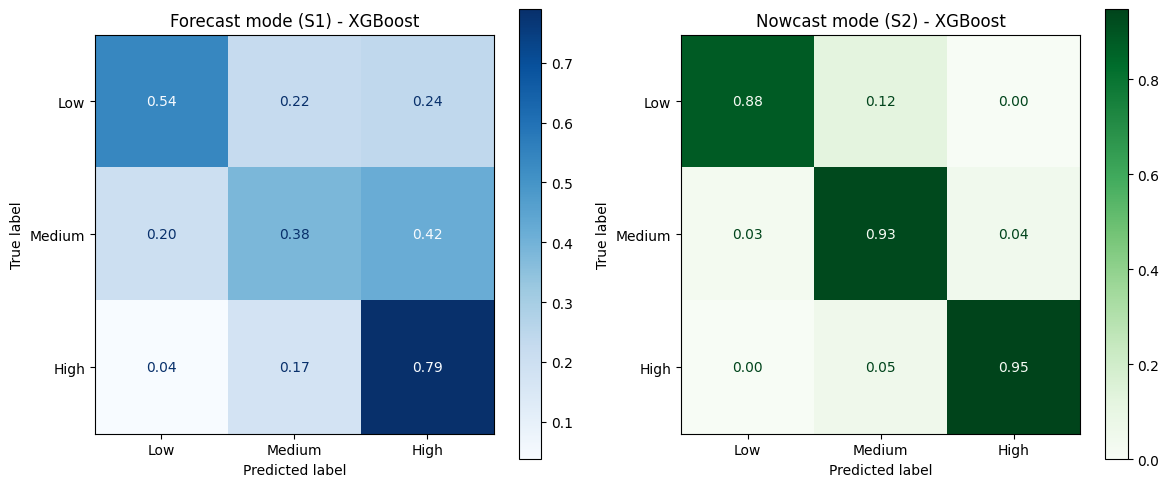

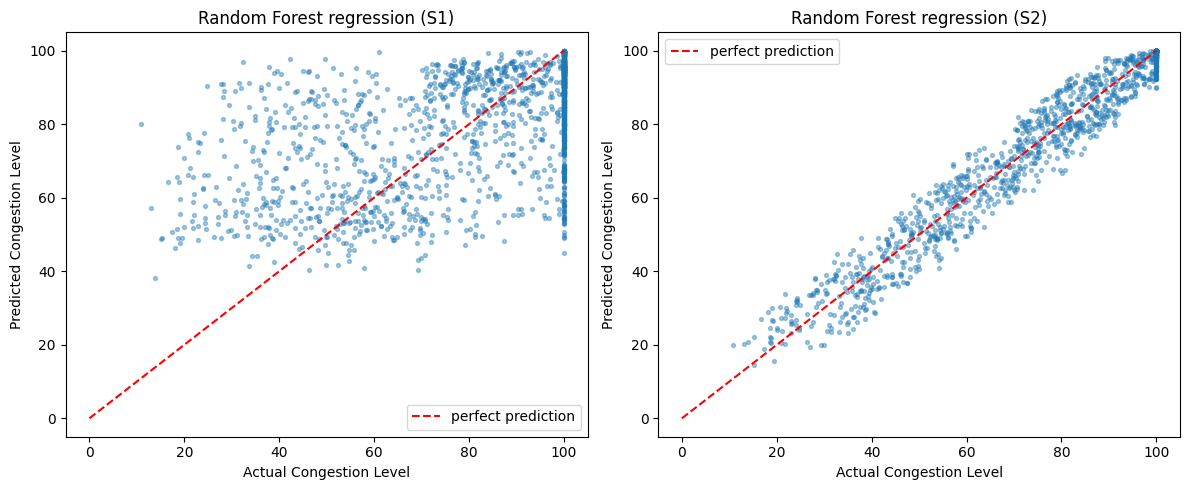

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# S1 final model: tuned XGBoost
pred_s1 = le.inverse_transform(xgb_grid.best_estimator_.predict(feature_sets["S1"][1]))
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, pred_s1, labels=labels, normalize="true",
    cmap="Blues", values_format=".2f", ax=axes[0])
axes[0].set_title("Forecast mode (S1) - XGBoost")

# S2 final model
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, s2_pred, labels=labels, normalize="true",
    cmap="Greens", values_format=".2f", ax=axes[1])
axes[1].set_title(f"Nowcast mode (S2) - {s2_name}")

plt.tight_layout()
plt.show()

# Predicted vs actual (regression, Random Forest)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, set_name in zip(axes, ["S1", "S2"]):
    Xtr_, Xte_ = feature_sets[set_name]
    rfr = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=-1).fit(Xtr_, y_train_reg)
    p = rfr.predict(Xte_)
    ax.scatter(y_test_reg, p, s=8, alpha=0.4)
    ax.plot([0, 100], [0, 100], "r--", label="perfect prediction")
    ax.set_xlabel("Actual Congestion Level")
    ax.set_ylabel("Predicted Congestion Level")
    ax.set_title(f"Random Forest regression ({set_name})")
    ax.legend()
plt.tight_layout()
plt.show()

## Phase 7, Step 1: Reload saved models and verify they reproduce test results

**What:** List the files in the models folder, load each saved object with joblib, and check that the reloaded models give the same test accuracy as before.

**Why:**
- The dashboard runs in a separate environment from this notebook. It will only have the saved files, so we must prove they work on their own.
- Reproducing 0.598 (S1) and 0.927 (S2) confirms nothing was lost in saving.
- We also load `model_meta.json`, which stores the exact column order each model expects. Models read inputs by position, so a wrong order would silently give wrong predictions.

In [42]:
import joblib, json, os

MODEL_DIR = "/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/models"
print("Files:", sorted(os.listdir(MODEL_DIR)))

xgb_s1 = joblib.load(os.path.join(MODEL_DIR, "xgb_s1.joblib"))
s2_loaded = joblib.load(os.path.join(MODEL_DIR, "s2_model.joblib"))
enc_loaded = joblib.load(os.path.join(MODEL_DIR, "onehot_encoder.joblib"))
le_loaded = joblib.load(os.path.join(MODEL_DIR, "label_encoder.joblib"))
with open(os.path.join(MODEL_DIR, "model_meta.json")) as f:
    meta = json.load(f)

print("S2 model type:", meta["s2_model_type"])
print("S1 columns:", len(meta["s1_columns"]), " S2 columns:", len(meta["s2_columns"]))

# Rebuild test inputs in the SAVED column order and rescore
Xte_s1 = feature_sets["S1"][1][meta["s1_columns"]]
Xte_s2 = feature_sets["S2"][1][meta["s2_columns"]]

p1 = le_loaded.inverse_transform(xgb_s1.predict(Xte_s1))
p2 = le_loaded.inverse_transform(s2_loaded.predict(Xte_s2))

print("S1 accuracy (reloaded):", round(accuracy_score(y_test_cls, p1), 3))
print("S2 accuracy (reloaded):", round(accuracy_score(y_test_cls, p2), 3))

Files: ['label_encoder.joblib', 'model_meta.json', 'onehot_encoder.joblib', 'rf_s1.joblib', 's2_model.joblib', 'xgb_s1.joblib']
S2 model type: XGBoost
S1 columns: 32  S2 columns: 34
S1 accuracy (reloaded): 0.598
S2 accuracy (reloaded): 0.927


## Phase 7, Step 0: Save the S2 model and the column-order file

**What:** Save the chosen Scenario 2 model and a `model_meta.json` file holding the exact column order of each feature set and the class thresholds.

**Why:**
- The dashboard only has saved files, not this notebook's memory. It needs the S2 model and a record of the exact input column order each model expects.
- Models read inputs by position, so a wrong column order would silently give wrong predictions.
- Storing the thresholds (60 and 100) means the dashboard explains classes with the same rules we trained with.

In [41]:
import joblib, json, os

MODEL_DIR = "/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# Safety check: these must still exist in memory
print("S2 model in memory:", s2_name)

joblib.dump(s2_model, os.path.join(MODEL_DIR, "s2_model.joblib"))

meta = {
    "s1_columns": list(feature_sets["S1"][0].columns),
    "s2_columns": list(feature_sets["S2"][0].columns),
    "s2_model_type": s2_name,
    "class_thresholds": {"low_below": LOW_CUT, "high_at_or_above": HIGH_CUT},
}
with open(os.path.join(MODEL_DIR, "model_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

print("Saved:", sorted(os.listdir(MODEL_DIR)))

S2 model in memory: XGBoost
Saved: ['label_encoder.joblib', 'model_meta.json', 'onehot_encoder.joblib', 'rf_s1.joblib', 's2_model.joblib', 'xgb_s1.joblib']


## Phase 7, Step 2: Build predict_congestion()

**What:** Write one function that takes raw user inputs (road, incident count, weather, roadwork, date, and optionally traffic volume and average speed), builds the exact feature row the trained model expects, and returns the predicted class with class probabilities.

**Why:**
- The dashboard only has saved files, so all feature building must happen inside a function that uses the saved encoder and the saved column order.
- Using the saved encoder guarantees the same one-hot columns as training. Using the saved column list guarantees the same order. A mismatch would silently give wrong predictions.
- Two modes: Forecast (S1) when volume/speed are not given, Nowcast (S2) when both are given. The function states which mode it used, so the user knows how reliable the answer is.
- Probabilities are returned, not just a label, because S1 accuracy is only about 60% and the user should see the uncertainty.

In [45]:
import pandas as pd

# Road -> Area lookup, saved so the dashboard doesn't need the CSV
road_to_area = df.groupby("Road/Intersection Name")["Area Name"].first().to_dict()
with open(os.path.join(MODEL_DIR, "road_to_area.json"), "w") as f:
    json.dump(road_to_area, f, indent=2)

# Models: S1 = tuned XGBoost, S2 = chosen S2 model (loaded earlier)
CLASSES = list(le_loaded.classes_)   # order of the model's probability columns

def predict_congestion(road, incidents, weather, roadwork, date,
                       traffic_volume=None, avg_speed=None):
    # Only one of volume/speed given is not allowed
    if (traffic_volume is None) != (avg_speed is None):
        raise ValueError("Give both Traffic Volume and Average Speed, or neither.")
    nowcast = traffic_volume is not None

    d = pd.to_datetime(date)
    raw = pd.DataFrame([{
        "Road/Intersection Name": road,
        "Weather Conditions": weather,
        "Weekday": d.day_name(),
    }])

    # One-hot columns from the SAVED encoder
    cat = pd.DataFrame(enc_loaded.transform(raw),
                       columns=enc_loaded.get_feature_names_out(
                           ["Road/Intersection Name", "Weather Conditions", "Weekday"]))

    row = cat.copy()
    row["Incident Reports"] = incidents
    row["Roadwork_Flag"] = 1 if roadwork == "Yes" else 0
    row["Is_Weekend"] = int(d.dayofweek >= 5)
    row["Month"] = d.month

    if nowcast:
        row["Traffic Volume"] = traffic_volume
        row["Average Speed"] = avg_speed
        columns, model, mode = meta["s2_columns"], s2_loaded, "Nowcast (S2)"
    else:
        columns, model, mode = meta["s1_columns"], xgb_s1, "Forecast (S1)"

    row = row[columns]                      # exact training column order
    proba = model.predict_proba(row)[0]
    probs = {str(c): float(p) for c, p in zip(CLASSES, proba)}
    label = str(max(probs, key=probs.get))

    return {"mode": mode, "area": road_to_area.get(road),
            "prediction": label, "probabilities": probs}

# --- Test it ---
print(predict_congestion("Sony World Junction", 2, "Clear", "No", "2024-03-15"))
print(predict_congestion("Sony World Junction", 2, "Clear", "No", "2024-03-15",
                         traffic_volume=55000, avg_speed=30))
print(predict_congestion("Silk Board Junction", 0, "Rain", "No", "2024-03-16",
                         traffic_volume=9000, avg_speed=55))

{'mode': 'Forecast (S1)', 'area': 'Koramangala', 'prediction': 'High', 'probabilities': {'High': 0.8130040168762207, 'Low': 0.03748695179820061, 'Medium': 0.1495089828968048}}
{'mode': 'Nowcast (S2)', 'area': 'Koramangala', 'prediction': 'High', 'probabilities': {'High': 0.9989750385284424, 'Low': 0.00013398571172729135, 'Medium': 0.0008909949683584273}}
{'mode': 'Nowcast (S2)', 'area': 'Electronic City', 'prediction': 'Low', 'probabilities': {'High': 0.00019430248357821256, 'Low': 0.998235821723938, 'Medium': 0.0015699113719165325}}


## Phase 8, Step 1: Verify saved files and record library versions

**What:** List all files in the models folder, and print the exact versions of the libraries the saved models depend on.

**Why:**
- The dashboard needs `road_to_area.json` as well as the models; this confirms it exists.
- Saved models (joblib files) are tied to library versions. Pinning the same versions in `requirements.txt` avoids load errors and silent behaviour changes on Streamlit Cloud.

In [46]:
import sklearn, xgboost, numpy, pandas, joblib, sys

print("Models folder:", sorted(os.listdir(MODEL_DIR)))
print()
print("python    ", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("xgboost   ", xgboost.__version__)
print("numpy     ", numpy.__version__)
print("pandas    ", pandas.__version__)
print("joblib    ", joblib.__version__)

Models folder: ['label_encoder.joblib', 'model_meta.json', 'onehot_encoder.joblib', 'rf_s1.joblib', 'road_to_area.json', 's2_model.joblib', 'xgb_s1.joblib']

python     3.13.18
scikit-learn 1.6.1
xgboost    3.4.1
numpy      2.4.6
pandas     2.2.3
joblib     1.6.0


## Phase 8, Step 2: Create src/predict.py (standalone prediction module)

**What:** Write predict_congestion() and the code that loads the saved models into a standalone file, then test it from the notebook exactly as the dashboard will use it.

**Why:**
- The dashboard has no access to notebook variables, so everything it needs must be loaded from files.
- Paths are built relative to the file's own location, so the same code works in Drive, on a laptop and on Streamlit Cloud.
- Testing the module here, before building the interface, separates "does the model code work?" from "does the dashboard work?".

In [47]:
%%writefile /content/drive/MyDrive/ML-Project/bangalore-traffic-ml/src/predict.py
import json
from pathlib import Path

import joblib
import pandas as pd

MODEL_DIR = Path(__file__).resolve().parent.parent / "models"

xgb_s1 = joblib.load(MODEL_DIR / "xgb_s1.joblib")
s2_model = joblib.load(MODEL_DIR / "s2_model.joblib")
encoder = joblib.load(MODEL_DIR / "onehot_encoder.joblib")
label_enc = joblib.load(MODEL_DIR / "label_encoder.joblib")
with open(MODEL_DIR / "model_meta.json") as f:
    meta = json.load(f)
with open(MODEL_DIR / "road_to_area.json") as f:
    road_to_area = json.load(f)

CLASSES = [str(c) for c in label_enc.classes_]   # order of probability columns
CAT_COLS = ["Road/Intersection Name", "Weather Conditions", "Weekday"]


def predict_congestion(road, incidents, weather, roadwork, date,
                       traffic_volume=None, avg_speed=None):
    if (traffic_volume is None) != (avg_speed is None):
        raise ValueError("Give both Traffic Volume and Average Speed, or neither.")
    nowcast = traffic_volume is not None

    d = pd.to_datetime(date)
    raw = pd.DataFrame([{
        "Road/Intersection Name": road,
        "Weather Conditions": weather,
        "Weekday": d.day_name(),
    }])
    cat = pd.DataFrame(encoder.transform(raw),
                       columns=encoder.get_feature_names_out(CAT_COLS))

    row = cat.copy()
    row["Incident Reports"] = incidents
    row["Roadwork_Flag"] = 1 if roadwork == "Yes" else 0
    row["Is_Weekend"] = int(d.dayofweek >= 5)
    row["Month"] = d.month

    if nowcast:
        row["Traffic Volume"] = traffic_volume
        row["Average Speed"] = avg_speed
        columns, model, mode = meta["s2_columns"], s2_model, "Nowcast (S2)"
    else:
        columns, model, mode = meta["s1_columns"], xgb_s1, "Forecast (S1)"

    row = row[columns]
    proba = model.predict_proba(row)[0]
    probs = {c: float(p) for c, p in zip(CLASSES, proba)}
    label = max(probs, key=probs.get)
    return {"mode": mode, "area": road_to_area.get(road),
            "prediction": label, "probabilities": probs}

Writing /content/drive/MyDrive/ML-Project/bangalore-traffic-ml/src/predict.py


In [48]:
import sys, importlib
sys.path.insert(0, "/content/drive/MyDrive/ML-Project/bangalore-traffic-ml/src")
import predict
importlib.reload(predict)

print(predict.predict_congestion("Sony World Junction", 2, "Clear", "No", "2024-03-15"))
print(predict.predict_congestion("Silk Board Junction", 0, "Rain", "No", "2024-03-16",
                                 traffic_volume=9000, avg_speed=55))

{'mode': 'Forecast (S1)', 'area': 'Koramangala', 'prediction': 'High', 'probabilities': {'High': 0.8130040168762207, 'Low': 0.03748695179820061, 'Medium': 0.1495089828968048}}
{'mode': 'Nowcast (S2)', 'area': 'Electronic City', 'prediction': 'Low', 'probabilities': {'High': 0.00019430248357821256, 'Low': 0.998235821723938, 'Medium': 0.0015699113719165325}}
